## Netflix Dataset Visualization

In [1]:
import pandas as pd

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [19]:
url="https://itv-contentbucket.s3.ap-south-1.amazonaws.com/Exams/AWP/pandas/Netflix.csv"
df=pd.read_csv(url)


In [20]:
df

,Title,Genre,Languages,Series or Movie,Hidden Gem Score,Country Availability,Runtime,Director,Writer,Actors,View Rating,IMDb Score,Rotten Tomatoes Score,Metacritic Score,Awards Nominated For,Boxoffice,Release Date,Netflix Release Date,Netflix Link,IMDb Votes
0,Lets Fight Ghost,"Crime, Drama, Fantasy, Horror, Romance","Swedish, Spanish",Series,4.3,Thailand,< 30 minutes,Tomas Alfredson,John Ajvide Lindqvist,"Kåre Hedebrant, Per Ragnar, Lina Leandersson, ...",R,7.9,98.0,82.0,57.0,"$2,122,065",12-Dec-08,04-03-2021,https://www.netflix.com/watch/81415947,205926.0
1,HOW TO BUILD A GIRL,Comedy,English,Movie,7.0,Canada,1-2 hour,Coky Giedroyc,Caitlin Moran,"Paddy Considine, Cleo, Beanie Feldstein, Dónal...",R,5.8,79.0,69.0,NaN,"$70,632",08-May-20,04-03-2021,https://www.netflix.com/watch/81041267,2838.0
2,Centigrade,"Drama, Thriller",English,Movie,6.4,Canada,1-2 hour,Brendan Walsh,"Brendan Walsh, Daley Nixon","Genesis Rodriguez, Vincent Piazza",Unrated,4.3,NaN,46.0,NaN,"$16,263",28-Aug-20,04-03-2021,https://www.netflix.com/watch/81305978,1720.0
3,ANNE+,Drama,Turkish,Series,7.7,"Belgium,Netherlands",< 30 minutes,NaN,NaN,"Vahide Perçin, Gonca Vuslateri, Cansu Dere, Be...",NaN,6.5,NaN,NaN,NaN,NaN,01-Oct-16,04-03-2021,https://www.netflix.com/watch/81336456,1147.0
4,Moxie,"Animation, Short, Drama",English,Movie,8.1,"Lithuania,Poland,France,Iceland,Italy,Spain,Gr...",1-2 hour,Stephen Irwin,NaN,Ragga Gudrun,NaN,6.3,NaN,NaN,4.0,NaN,22-Sep-11,04-03-2021,https://www.netflix.com/watch/81078393,63.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15480,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## IMDb rating distribution

In [5]:
#--- calculating total ratings 
df["score_numeric"] = pd.to_numeric(df["IMDb Score"], errors="coerce")
df["gemscore"]=pd.to_numeric(df["Hidden Gem Score"],errors="coerce")
df["rating"]= df["score_numeric"] + df["gemscore"]

Text(0, 0.5, 'number of movies')

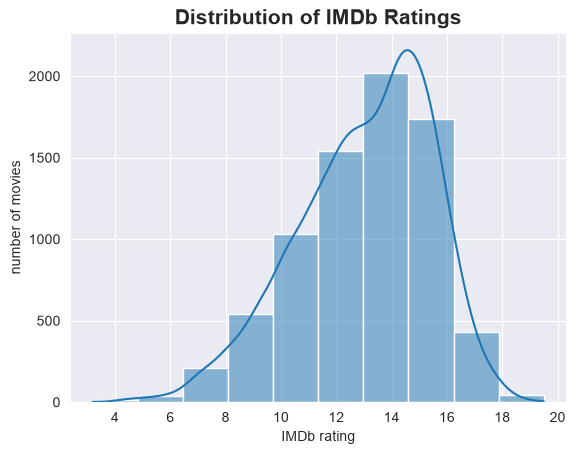

In [18]:
sns.histplot(data=df, x="rating", bins=10, kde= True)
plt.title('Distribution of IMDb Ratings', fontsize=15, fontweight="bold")
plt.xlabel('IMDb rating')
plt.ylabel('number of movies') 
# insight- most movies are concentrated around a particular rating range(12-16)

## Top 10 directors by number of films

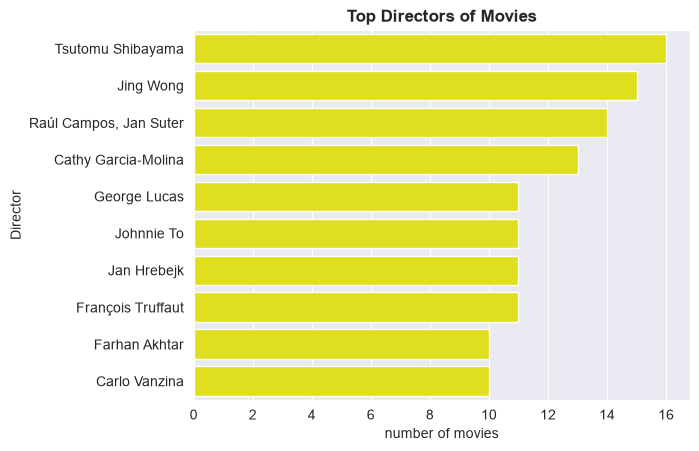

In [7]:
topdirector=df["Director"].value_counts().head(10)

sns.set_style("darkgrid")
sns.barplot(x=topdirector.values, y=topdirector.index, color="yellow")
plt.title('Top Directors of Movies', fontweight="bold")
plt.xlabel('number of movies')

plt.show()

## country-wise rating distribution

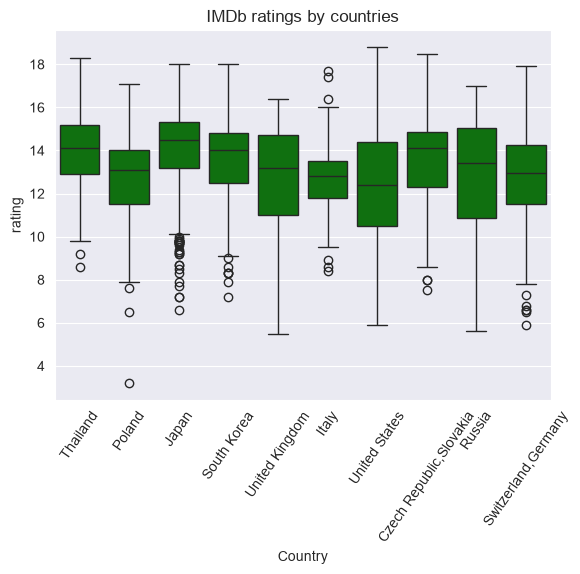

In [8]:
#--- fetching the top 10 countries to analyse rating distribution

topcountries=df["Country Availability"].value_counts().head(10).index
sns.boxplot(data=df[df["Country Availability"].isin(topcountries)],x= 'Country Availability', y='rating',color="Green")
plt.xticks(rotation=55)
plt.title('IMDb ratings by countries')
plt.xlabel('Country')
plt.show()

## Movies or Series comparison

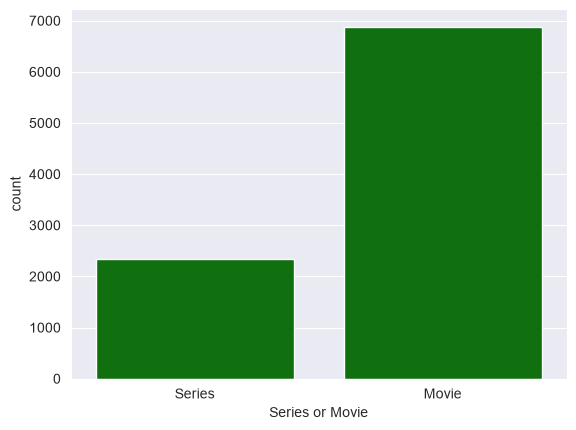

In [9]:
sns.countplot(data=df,x='Series or Movie', color="Green") 
plt.show()

#-- tells us the number of movies or series 

## IMDb Score comparison of movies & series

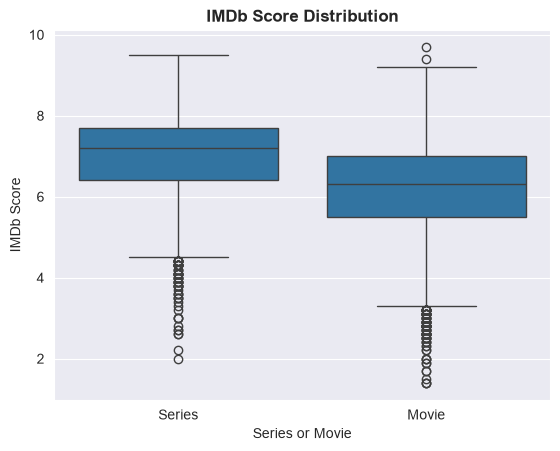

In [10]:
sns.boxplot( data=df, x="Series or Movie", y="IMDb Score")
plt.title('IMDb Score Distribution',fontweight="bold")
plt.ylabel('IMDb Score')
plt.show()

#--- outlers can be identified in IMDb scores, mostly the scores are spread in the range of 5-8

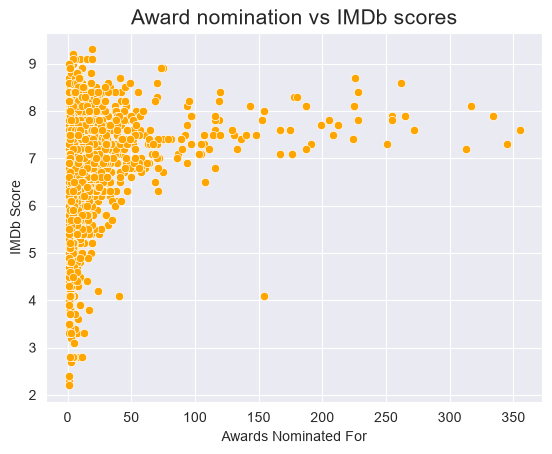

In [11]:
sns.scatterplot(data=df,x="Awards Nominated For",y="IMDb Score", color="Orange")
plt.title('Award nomination vs IMDb scores', fontsize=15)

plt.show()

### average boxoffice collection & ratings by runtime

In [12]:
df["Boxoffice_numeric"] = pd.to_numeric(df["Boxoffice"].astype("string").str.replace(r"[$,]","", regex=True),errors="coerce")
df["Boxoffice_numeric"]=df["Boxoffice_numeric"].astype(float).fillna(df["Boxoffice_numeric"].median())
runtime=df['Runtime'].unique()
print(runtime)

runtime_analysis=df.groupby("Runtime").agg(
    average_rating=("rating","mean"),
    average_boxoffice_collection=("Boxoffice_numeric","mean"))

runtime_analysis['average_boxoffice_collection']=runtime_analysis['average_boxoffice_collection'].round(2)
print(runtime_analysis)

<StringArray>
['< 30 minutes', '1-2 hour', '> 2 hrs', '30-60 mins', nan]
Length: 5, dtype: str
              average_rating  average_boxoffice_collection
Runtime                                                   
1-2 hour           12.517752                    7191329.71
30-60 mins         14.286275                    2598863.50
< 30 minutes       14.248491                    4239111.84
> 2 hrs            12.805258                   12796663.29


C:\Users\user\AppData\Local\Temp\ipykernel_5956\3669827001.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(runtime_analysis, x='Runtime',y=cols, ax=ax, edgecolor="black", palette=runtime_typecolor )
C:\Users\user\AppData\Local\Temp\ipykernel_5956\3669827001.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(runtime_analysis, x='Runtime',y=cols, ax=ax, edgecolor="black", palette=runtime_typecolor )


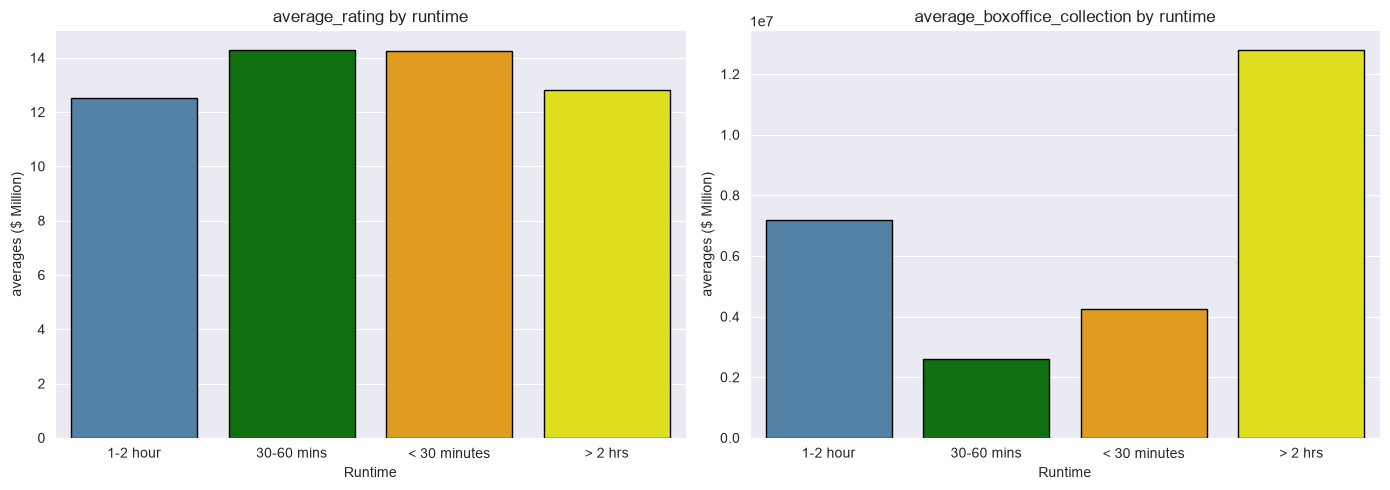

In [13]:
fig, axes=plt.subplots(1,2, figsize=(14,5))
cols=["average_rating","average_boxoffice_collection"]
runtime_typecolor={"< 30 minutes":"orange","1-2 hour":"steelblue","> 2 hrs":"Yellow","30-60 mins":"Green","nan":"Red"}

for cols, ax in zip(cols,axes):
    sns.barplot(runtime_analysis, x='Runtime',y=cols, ax=ax, edgecolor="black", palette=runtime_typecolor )
    ax.set_title(f'{cols} by runtime')
    ax.set_xlabel("Runtime")
    ax.set_ylabel("averages ($ Million)")

plt.tight_layout()
plt.show()

## linear relationship using heatmap

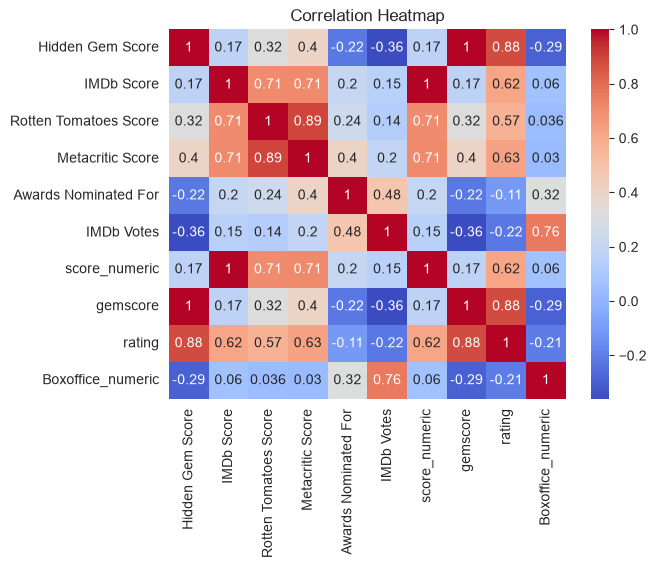

In [14]:
# --- visulizing the strngth & direction of linear relationships between the numerical values.

Data=df.corr(numeric_only=True)
sns.heatmap(Data,annot=True,cmap="coolwarm")

plt.title('Correlation Heatmap')
plt.show()


## RElationship between IMDb score and Genre

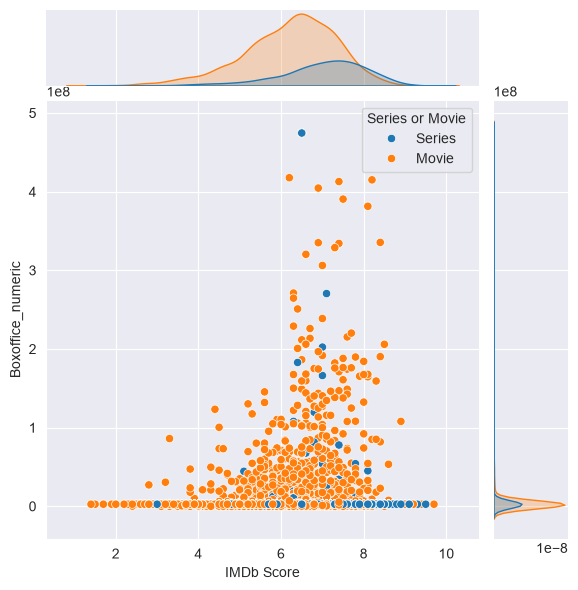

In [16]:
sns.jointplot(data=df,x="IMDb Score",y="Boxoffice_numeric", hue="Series or Movie", kind="scatter")
plt.show()

In [21]:

Data=df.corr(numeric_only=True)
Data

,Hidden Gem Score,IMDb Score,Rotten Tomatoes Score,Metacritic Score,Awards Nominated For,IMDb Votes
Hidden Gem Score,1.000000,0.172506,0.319640,0.401181,-0.217399,-0.360737
IMDb Score,0.172506,1.000000,0.706411,0.712748,0.204715,0.153613
Rotten Tomatoes Score,0.319640,0.706411,1.000000,0.894161,0.240975,0.136992
Metacritic Score,0.401181,0.712748,0.894161,1.000000,0.399707,0.196478
Awards Nominated For,-0.217399,0.204715,0.240975,0.399707,1.000000,0.482001
IMDb Votes,-0.360737,0.153613,0.136992,0.196478,0.482001,1.000000
